# Exploratory analysis of the German day-ahead power market (Oct 2018 - Sep 2020)

Hourly DE-LU day-ahead prices with load, wind, solar and weather. The goal is to understand **what moves the price** before building any forecast: trend, daily and weekly seasonality, the merit-order effect of wind, negative prices and how much the price "remembers" its own past.

Data: the offline sample in `data/sample/` (built from the [energy-data-pipeline](https://github.com/Salittars/energy-data-pipeline) DuckDB table plus OPSD solar). Set `SOURCE = "duckdb"` and `DUCKDB_PATH` to read the pipeline output directly.

In [1]:
import sys
sys.path.insert(0, "..")

from IPython.display import display
import pandas as pd

from energy_eda import data, features as F, plots
import matplotlib.pyplot as plt
%matplotlib inline

SOURCE = "sample"          # "sample" | "duckdb" | "opsd"
DUCKDB_PATH = None         # e.g. "../../energy-data-pipeline/data/energy.duckdb"
OPSD_CSV = None            # optional local OPSD CSV (adds solar to the duckdb source)

df = F.add_features(data.load(SOURCE, DUCKDB_PATH, OPSD_CSV))
plots.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
print(f"{len(df):,} hours, {df.index.min():%Y-%m-%d} to {df.index.max():%Y-%m-%d} (UTC)")

17,544 hours, 2018-10-01 to 2020-09-30 (UTC)


## 1. First look at the data

In [2]:
df[["price_eur_mwh", "load_mw", "wind_generation_mw", "solar_generation_mw", "residual_load_mw",
    "wind_speed_100m_ms_mean", "temperature_c_mean"]].describe().T

,count,mean,std,min,25%,50%,75%,max
price_eur_mwh,"17,543.00",35.80,18.14,-90.01,26.70,36.15,46.02,200.04
load_mw,"17,544.00","55,148.83","9,987.65","31,923.00","47,012.00","54,724.50","63,441.75","76,925.00"
wind_generation_mw,"17,544.00","14,372.82","10,314.53",136.00,"6,176.00","11,728.00","20,347.50","46,064.00"
solar_generation_mw,"17,544.00","5,005.54","7,653.00",0.00,0.00,155.50,"8,003.00","32,947.00"
residual_load_mw,"17,544.00","35,770.46","12,589.81",648.00,"27,416.00","36,199.50","44,504.00","72,655.00"
wind_speed_100m_ms_mean,"17,544.00",4.93,2.13,1.01,3.40,4.52,6.04,15.15
temperature_c_mean,"17,544.00",11.41,7.33,-5.85,5.52,10.66,16.80,35.42


In [3]:
print("Missing values per column:")
print(df[data.COLUMNS].isna().sum().to_string())

Missing values per column:
price_eur_mwh              1
load_mw                    0
wind_generation_mw         0
solar_generation_mw        0
wind_speed_100m_ms_mean    0
temperature_c_mean         0


Only one price hour is missing (the pipeline already interpolated the short gaps). It is left as NaN for the descriptive charts and interpolated only where a method needs a gap-free series (ACF, STL).

## 2. Price over time with rolling means

A 7-day and a 30-day rolling mean smooth out the hourly noise so the level shift becomes visible.

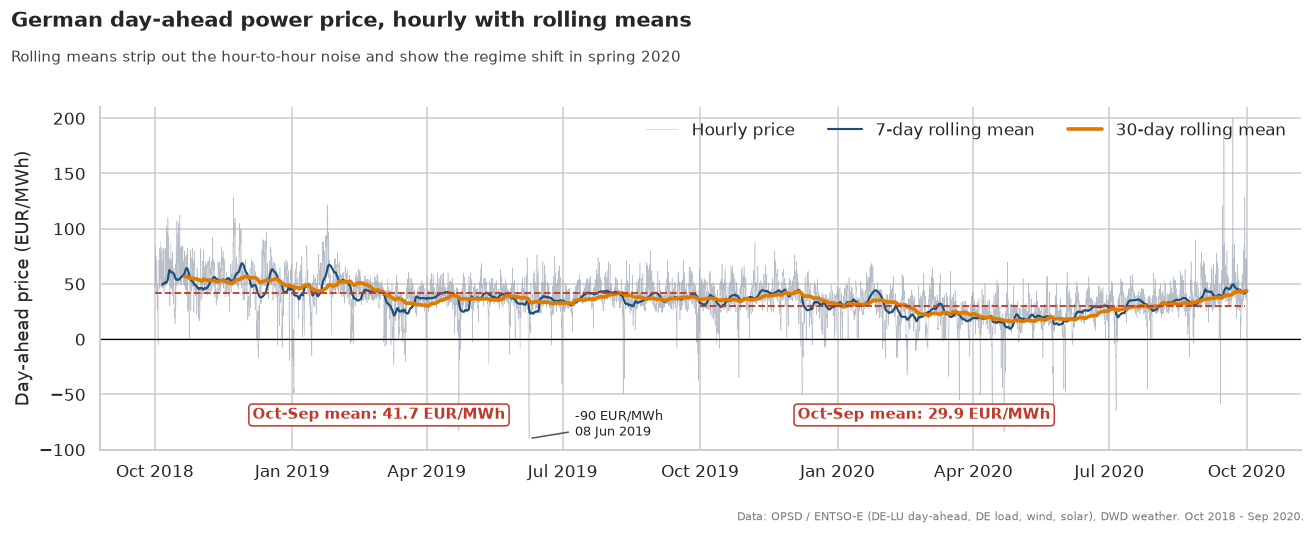

Takeaway: The average day-ahead price fell from 41.7 EUR/MWh (Oct 2018-Sep 2019) to 29.9 EUR/MWh (Oct 2019-Sep 2020), a 28% drop, with the 30-day mean bottoming at 16.0 EUR/MWh around 03 May 2020.


In [4]:
fig, takeaway, nums = plots.price_timeseries(df)
display(fig)
plt.close(fig)
print("Takeaway:", takeaway)

## 3. Daily and weekly seasonality

Mean price for each hour of the day (Berlin local time, so daylight-saving changes do not blur the peaks) and each weekday.

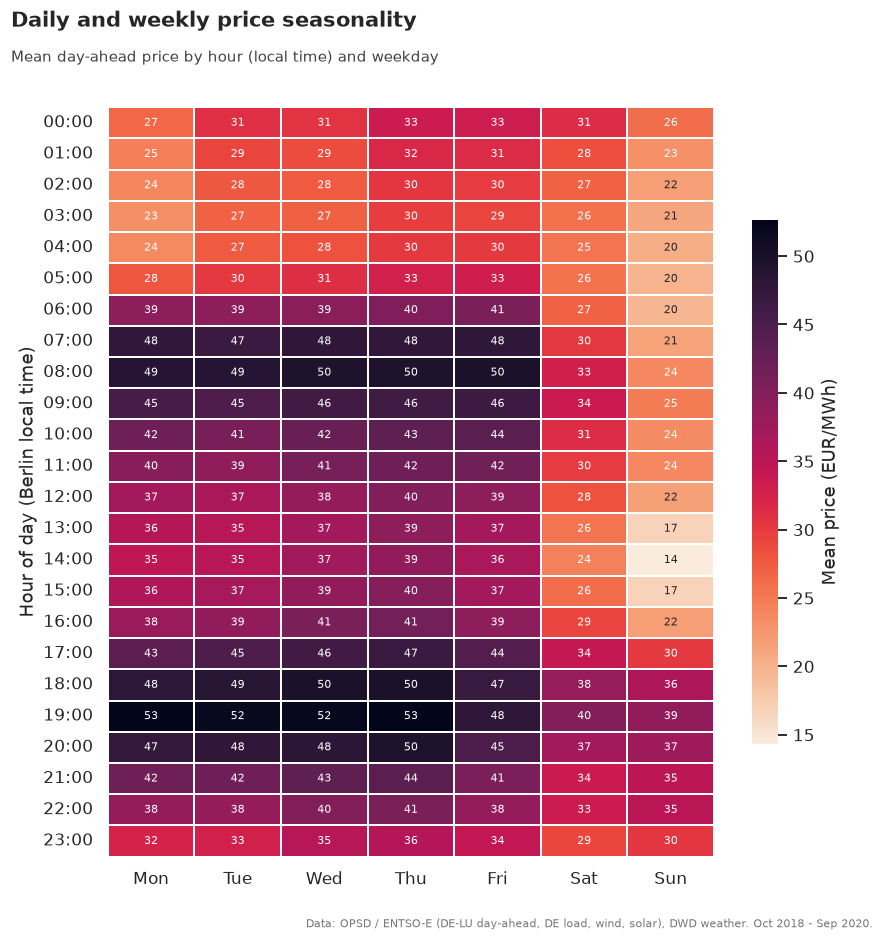

Takeaway: Prices follow the working week: the highest average is 52.7 EUR/MWh on Thu at 19:00, the lowest 14.3 EUR/MWh on Sun at 14:00 when demand is low and solar output peaks; Sundays average 25.2 vs 39.0 EUR/MWh on weekdays.


In [5]:
fig, takeaway, nums = plots.seasonality_heatmap(df)
display(fig)
plt.close(fig)
print("Takeaway:", takeaway)

## 4. Price vs wind, and vs residual load

Residual load = load - wind - solar: the demand that conventional (gas, coal, lignite, nuclear) plants still have to cover.

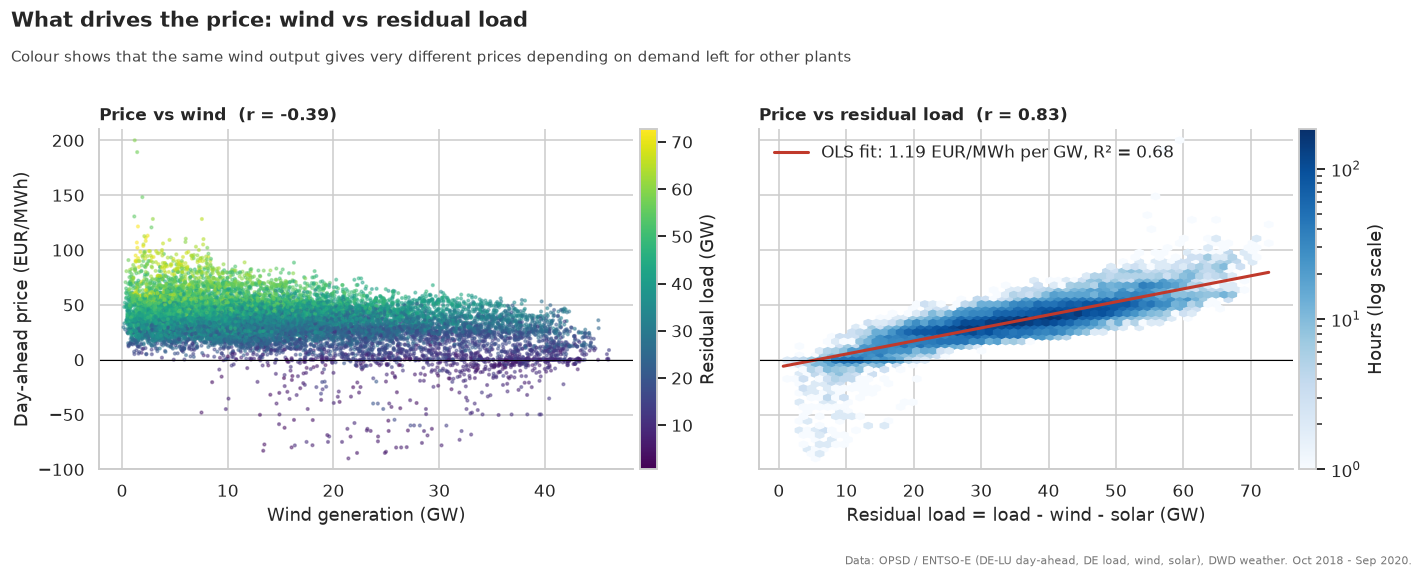

Takeaway: Wind alone explains only 15% of price variance (r = -0.39), but residual load explains 68% (r = 0.83); each extra GW of residual load adds about 1.19 EUR/MWh.


In [6]:
fig, takeaway, nums = plots.price_vs_wind_residual(df)
display(fig)
plt.close(fig)
print("Takeaway:", takeaway)

## 5. Merit-order effect by wind decile

Split all hours into ten equal groups by wind output and compare the price distribution in each group.

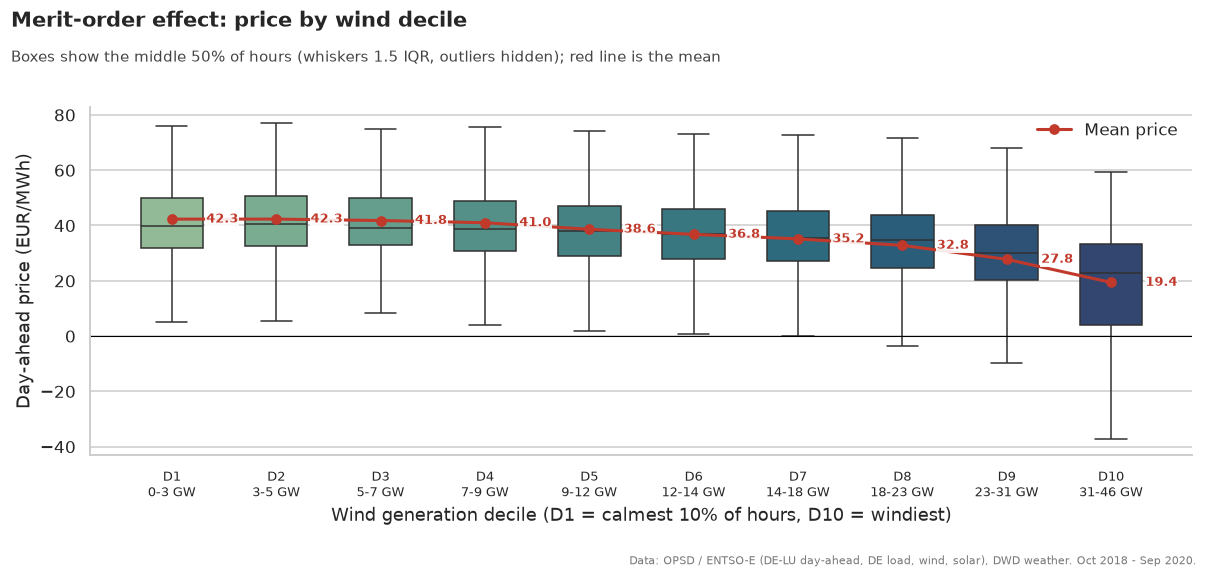

Takeaway: The merit-order effect: in the windiest 10% of hours (30.7-46.1 GW) the mean price is 19.4 EUR/MWh vs 42.3 in the calmest 10%, 54% lower, and that decile holds 265 of the 484 negative-price hours.


In [7]:
fig, takeaway, nums = plots.merit_order_deciles(df)
display(fig)
plt.close(fig)
print("Takeaway:", takeaway)

In [8]:
F.wind_deciles(df)

,wind_min_gw,wind_max_gw,mean_price,median_price,negative_hours,hours
wind_decile,,,,,,
1,0.14,3.29,42.30,39.92,0,1755
2,3.29,5.23,42.32,40.45,0,1754
3,5.23,7.18,41.80,39.02,0,1754
4,7.18,9.30,41.00,38.83,3,1754
5,9.30,11.73,38.64,37.94,6,1756
6,11.73,14.42,36.80,36.84,10,1754
7,14.43,18.09,35.15,35.35,42,1754
8,18.09,23.08,32.83,34.88,58,1753
9,23.09,30.69,27.78,29.95,100,1754


## 6. Negative-price hours per month

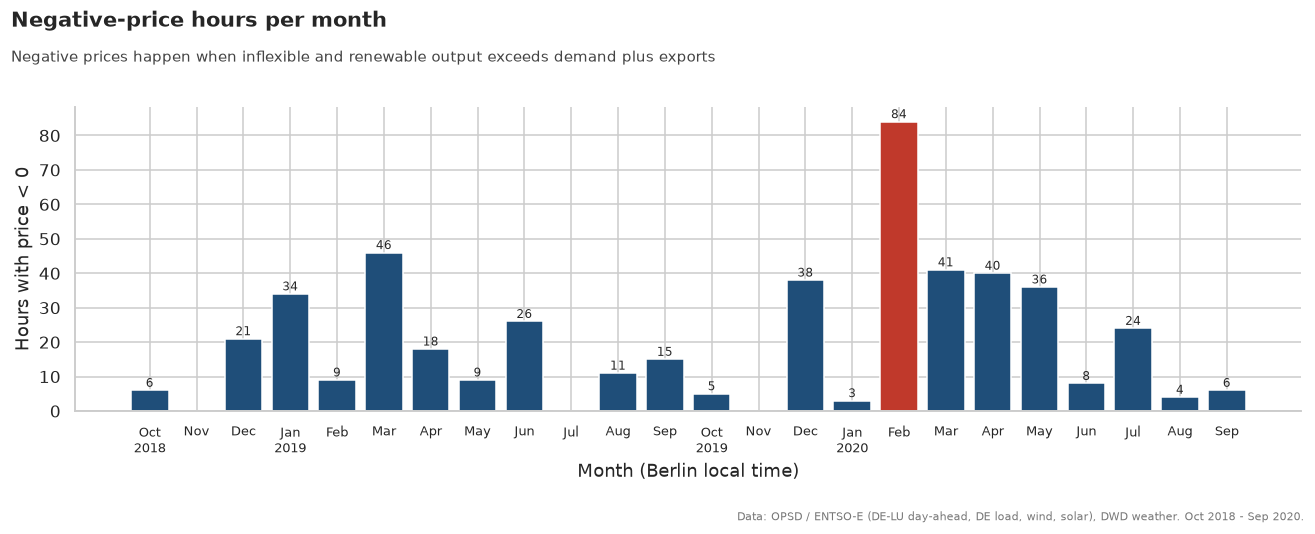

Takeaway: 484 hours had negative prices (195 in the first year, 289 in the second); the worst month was February 2020 with 84 hours, and 65% of all negative hours fell on weekends.


In [9]:
fig, takeaway, nums = plots.negative_prices_by_month(df)
display(fig)
plt.close(fig)
print("Takeaway:", takeaway)

In [10]:
neg = df[df.price_eur_mwh < 0]
print(f"Mean price in negative hours: {neg.price_eur_mwh.mean():.1f} EUR/MWh, lowest {neg.price_eur_mwh.min():.2f}")
print("Negative hours by local hour of day (top 5):")
print(neg.hour_local.value_counts().head(5).to_string())

Mean price in negative hours: -16.2 EUR/MWh, lowest -90.01
Negative hours by local hour of day (top 5):
hour_local
14    45
13    40
15    39
3     35
2     34


## 7. Distributions of load, wind and residual load

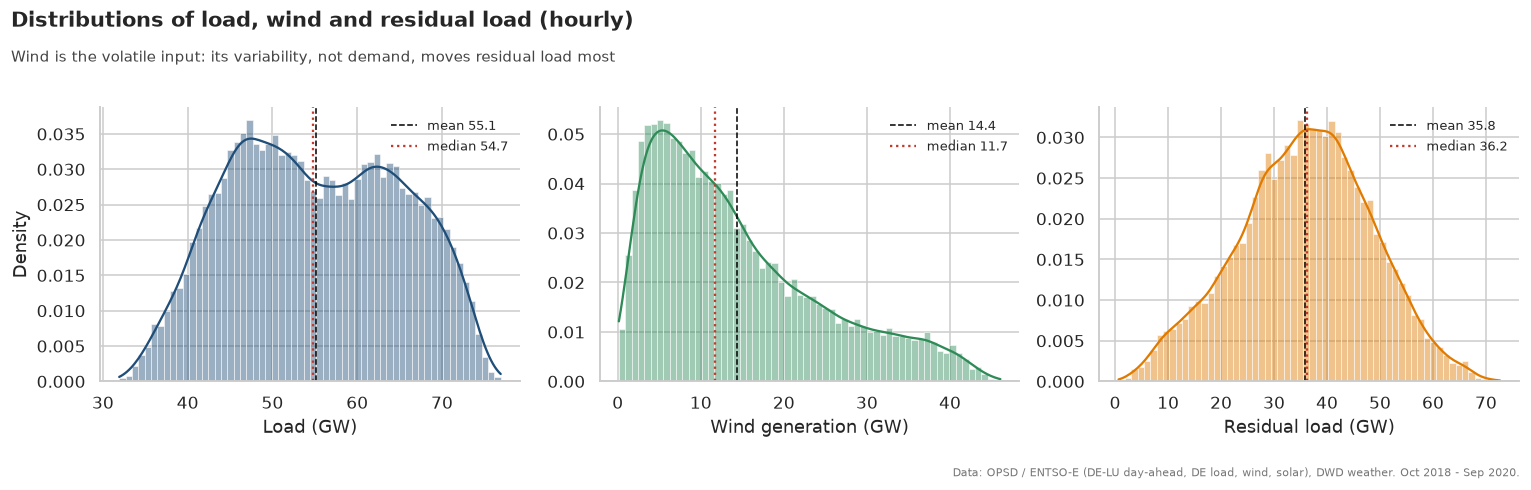

Takeaway: Load stays inside a narrow band (31.9-76.9 GW, coefficient of variation 0.18) with two humps for nights/weekends and working hours, while wind is right-skewed (skew 0.90, median 11.7 vs mean 14.4 GW, CV 0.72) and runs from 3.3 to 30.7 GW between its 10th and 90th percentiles.


In [11]:
fig, takeaway, nums = plots.load_wind_distributions(df)
display(fig)
plt.close(fig)
print("Takeaway:", takeaway)

## 8. Autocorrelation (ACF) and partial autocorrelation (PACF) of price

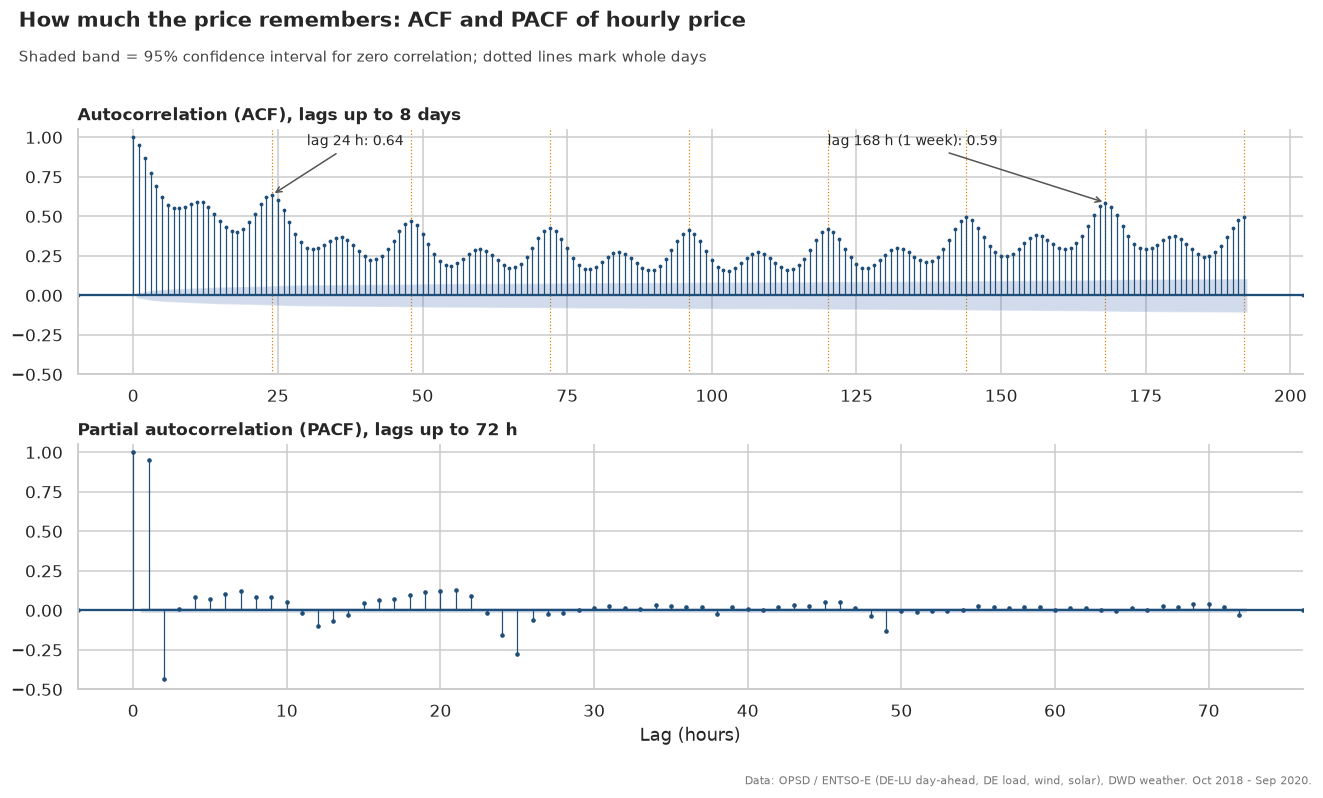

Takeaway: Price is highly persistent: correlation with the previous hour is 0.95, it falls to 0.40 at 18 h, climbs back to 0.64 at 24 h and peaks again at 0.59 after one week, so yesterday's and last week's same hour are natural forecasting features.


In [12]:
fig, takeaway, nums = plots.price_acf_pacf(df)
display(fig)
plt.close(fig)
print("Takeaway:", takeaway)

## 9. STL decomposition of the daily average price

STL (Seasonal-Trend decomposition using LOESS) with a 7-day period, robust to outliers.

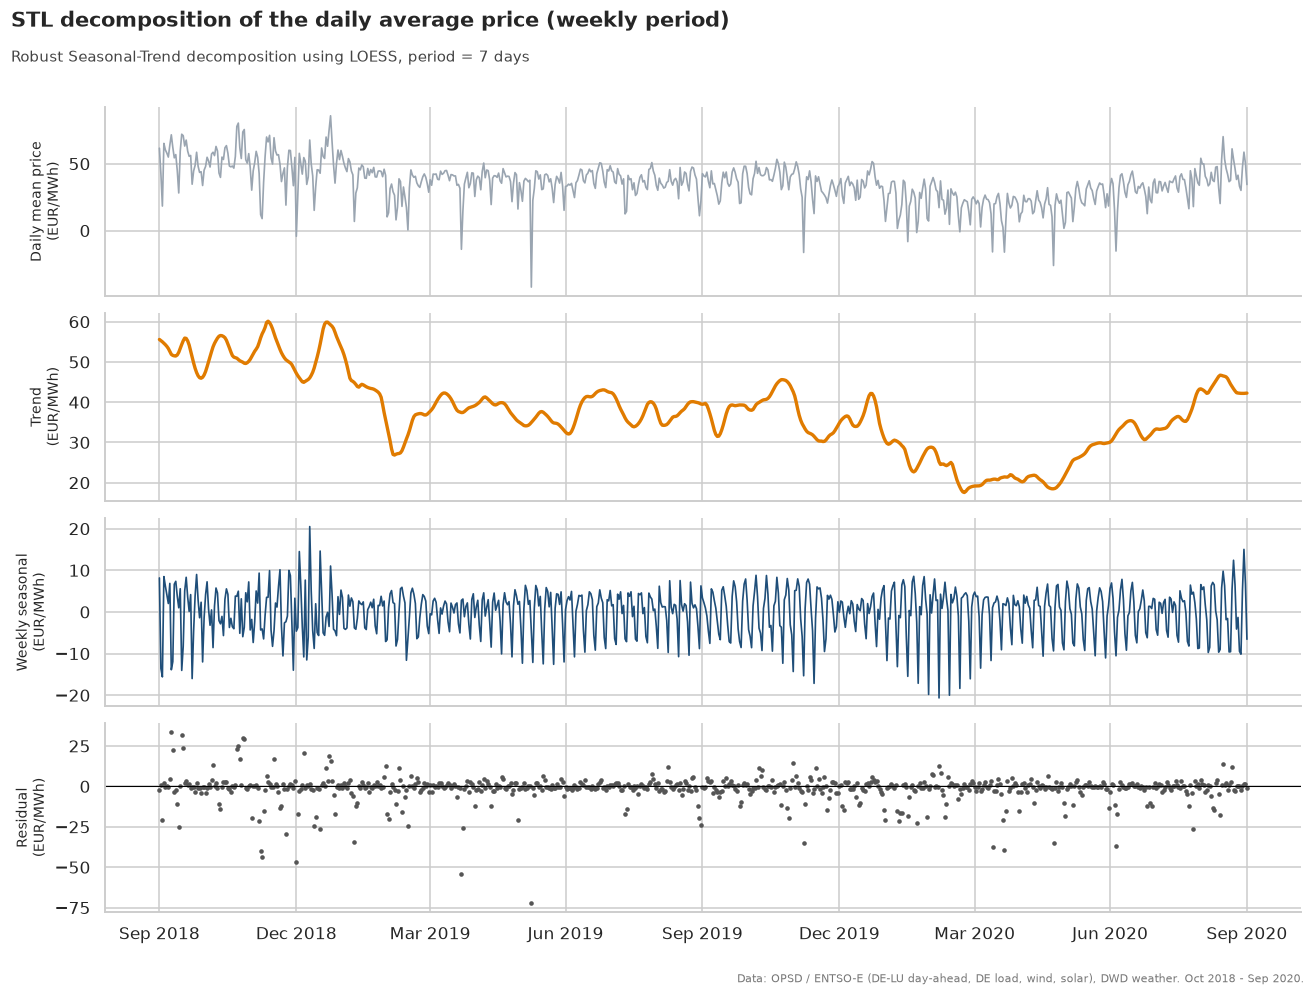

Takeaway: STL splits the daily price into a trend that falls from 55.6 to a low of 17.5 EUR/MWh (Mar 2020), a weekly cycle worth -8.6 EUR/MWh on Sundays and +2.5 on weekdays, and a residual that still carries 34% of the variance (weather and fuel shocks).


In [13]:
fig, takeaway, nums = plots.stl_decomposition(df)
display(fig)
plt.close(fig)
print("Takeaway:", takeaway)

## 10. Correlation matrix

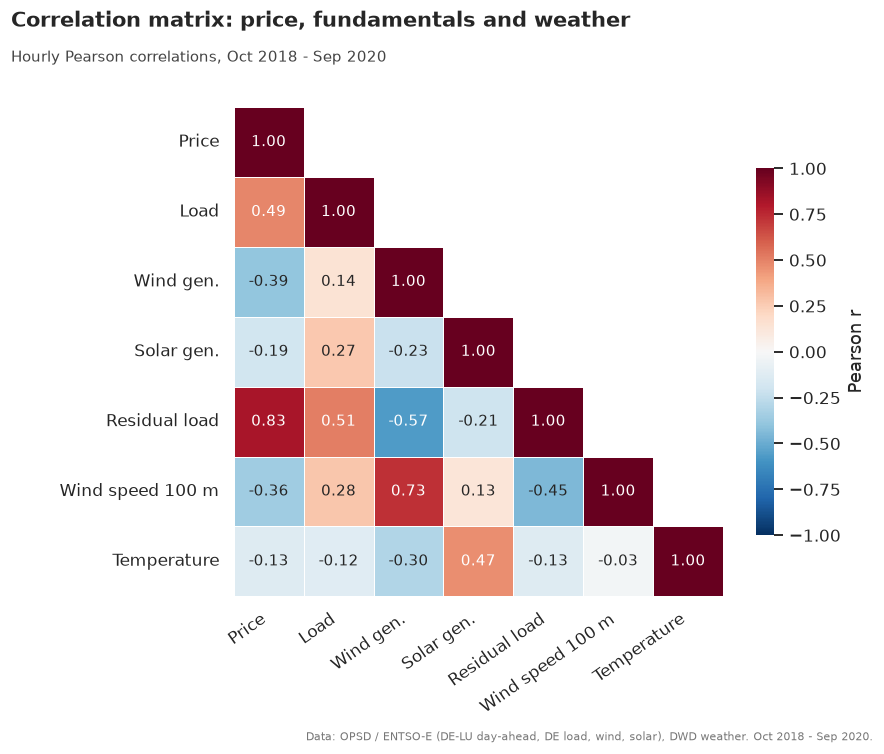

Takeaway: Residual load is the single best linear correlate of price (r = 0.83), ahead of load (0.49) and wind (-0.39); the 4-station wind speed tracks national wind output at r = 0.73.


In [14]:
fig, takeaway, nums = plots.correlation_matrix(df)
display(fig)
plt.close(fig)
print("Takeaway:", takeaway)

## Summary

- **Level:** the average price fell by roughly a quarter between the two years, with the lowest prices in spring 2020 (low demand, strong renewables, cheap gas and coal).
- **Seasonality:** strong daily (morning and 19:00 peaks) and weekly (weekend discount) patterns; any model needs hour-of-day and weekday features, in local time.
- **Fundamentals:** residual load explains about two thirds of the hourly price variance on its own; wind alone explains much less, because the same wind output matters very differently at 3 am on a Sunday than at 7 pm on a Thursday.
- **Merit order:** the windiest 10% of hours are more than 50% cheaper than the calmest 10% and contain most negative-price hours.
- **Memory:** price autocorrelation peaks at 24 h and 168 h, so lagged prices at those lags are natural features for a day-ahead forecast.

Next step: a day-ahead price model (gradient boosting or a regularised linear model) on residual-load forecasts, calendar features and lagged prices, evaluated with a rolling-origin backtest.